In [1]:
%pip install pandas numpy matplotlib scikit-learn plotly joblib

Note: you may need to restart the kernel to use updated packages.


In [17]:
import re
import warnings
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
import joblib

from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    log_loss
)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

RANDOM_STATE = 42
# Recency weighting: two-year half-life
HALF_LIFE_DAYS = 730
PSG_NAME = "Paris Saint-Germain"

print("Libraries imported successfully.")

Libraries imported successfully.


In [18]:
from pathlib import Path

# Use the folder where your notebook and season files are located
DATA_FOLDER = Path(".")
OUTPUT_FOLDER = Path("dashboard")

# Create the dashboard folder if it doesn't exist
OUTPUT_FOLDER.mkdir(exist_ok=True)

print("Notebook's current folder:", Path.cwd())
print("Text files found:")

for file in DATA_FOLDER.glob("*.txt"):
    print(file.name)

Notebook's current folder: /Users/raosahebshinde/Downloads/data_math 215
Text files found:
cl.txt_24_25.txt
cl.txt_15_16.txt
cl.txt_20_21.txt
cl.txt_18_19.txt
cl.txt_13_14.txt
cl.txt_22_23.txt
cl.txt_11_12.txt
cl.txt_25_26.txt
cl.txt_16_17.txt
cl.txt_14_15.txt
cl.txt_23_24.txt
cl.txt_21_22.txt
cl.txt_12_13.txt
cl.txt_17_18.txt
cl.txt_19_20.txt


In [19]:
DATA_FOLDER = Path(".")
OUTPUT_FOLDER = Path("dashboard")
OUTPUT_FOLDER.mkdir(exist_ok=True)

In [20]:
# Find all season text files
season_files = sorted(DATA_FOLDER.glob("*.txt"))

# Check how many files we found
print("Number of season files:", len(season_files))

# Open the first file
with open(season_files[0], "r", encoding="utf-8") as file:
    sample_data = file.read()

# Display the first 40 lines
print(sample_data[:3000])

Number of season files: 15
= UEFA Champions League 2011/12

# Date       Tue Sep 13 2011 - Sat May 19 2012 (249d)
# Teams      32
# Matches    125



▪ Group A
  Wed Sep 14 2011
    20:45  Manchester City (ENG)   v SSC Napoli (ITA)         1-1 (0-0)
           Villarreal CF (ESP)     v Bayern München (GER)     0-2 (0-1)
  Tue Sep 27
    20:45  Bayern München (GER)    v Manchester City (ENG)    2-0 (2-0)
           SSC Napoli (ITA)        v Villarreal CF (ESP)      2-0 (2-0)
  Tue Oct 18
    20:45  Manchester City (ENG)   v Villarreal CF (ESP)      2-1 (1-1)
           SSC Napoli (ITA)        v Bayern München (GER)     1-1 (1-1)
  Wed Nov 2
    20:45  Bayern München (GER)    v SSC Napoli (ITA)         3-2 (3-1)
           Villarreal CF (ESP)     v Manchester City (ENG)    0-3 (0-2)
  Tue Nov 22
    20:45  Bayern München (GER)    v Villarreal CF (ESP)      3-1 (2-0)
           SSC Napoli (ITA)        v Manchester City (ENG)    2-1 (1-1)
  Wed Dec 7
    20:45  Manchester City (ENG)   v Ba

In [21]:
DATE_PATTERN = re.compile(
    r"^(Mon|Tue|Wed|Thu|Fri|Sat|Sun)\s+"
    r"(Jan|Feb|Mar|Apr|May|Jun|Jul|Aug|Sep|Oct|Nov|Dec)\s+"
    r"\d{1,2}\s+\d{4}$"
)

MATCH_PATTERN = re.compile(
    r"^\s*(?:(\d{1,2}:\d{2})\s+)?"
    r"(.+?)\s+v\s+(.+?)\s+"
    r"(\d+)\s*[-–]\s*(\d+)"
    r"(?:\s+\([^)]*\))?\s*$",
    flags=re.IGNORECASE
)

def parse_openfootball_file(file_path):
    # Parse match rows from one season file.
    current_date = None
    parsed_matches = []
    unmatched_lines = []

    with open(file_path, "r", encoding="utf-8") as file:
        lines = file.readlines()

    for line_number, raw_line in enumerate(lines, start=1):
        line = raw_line.strip()

        if not line or line.startswith("#"):
            continue

        if DATE_PATTERN.match(line):
            try:
                current_date = datetime.strptime(line, "%a %b %d %Y")
            except ValueError:
                current_date = None
            continue

        match = MATCH_PATTERN.match(line)

        if match and current_date is not None:
            match_time, home_team, away_team, home_goals, away_goals = match.groups()
            parsed_matches.append({
                "date": current_date,
                "home_team": home_team.strip(),
                "away_team": away_team.strip(),
                "home_goals": int(home_goals),
                "away_goals": int(away_goals),
                "source_file": file_path.name
            })
        elif re.search(r"\bv\b", line, flags=re.IGNORECASE):
            unmatched_lines.append((file_path.name, line_number, line))

    return parsed_matches, unmatched_lines


all_matches = []
parser_warnings = []

for season_file in season_files:
    season_matches, unmatched = parse_openfootball_file(season_file)
    all_matches.extend(season_matches)
    parser_warnings.extend(unmatched)

matches = pd.DataFrame(all_matches)

if matches.empty:
    raise ValueError(
        "No matches were parsed. Check that the text files use the expected "
        "OpenFootball date and score format."
    )

matches["date"] = pd.to_datetime(matches["date"])
matches = matches.drop_duplicates(
    subset=["date", "home_team", "away_team", "home_goals", "away_goals"]
)
matches = matches.sort_values("date").reset_index(drop=True)

print("Parsed matches:", len(matches))
print("Teams:", len(set(matches["home_team"]) | set(matches["away_team"])))
print("Date range:", matches["date"].min().date(), "to", matches["date"].max().date())
print("Files contributing matches:", matches["source_file"].nunique())

if parser_warnings:
    print("\\nSome lines containing 'v' were not parsed. First examples:")
    for warning in parser_warnings[:10]:
        print(warning)

display(matches.head())

Parsed matches: 1973
Teams: 136
Date range: 2011-09-14 to 2026-01-20
Files contributing matches: 15
\nSome lines containing 'v' were not parsed. First examples:
('cl.txt_11_12.txt', 194, '20:45  APOEL Nikosia (CYP)     v Olympique Lyonnais (FRA)  4-3 pen. 1-0 a.e.t. (1-0, 1-0)')
('cl.txt_11_12.txt', 200, '20:45  Chelsea FC (ENG)        v SSC Napoli (ITA)         4-1 a.e.t. (3-1, 1-0)')
('cl.txt_11_12.txt', 227, '20:45  Real Madrid (ESP)       v Bayern München (GER)     1-3 pen. 2-1 a.e.t. (2-1, 2-1)')
('cl.txt_11_12.txt', 232, '20:45  Bayern München (GER)    v Chelsea FC (ENG)         3-4 pen. 1-1 a.e.t. (1-1, 0-0)')
('cl.txt_13_14.txt', 233, '20:45  Real Madrid (ESP)       v Atlético Madrid (ESP)    4-1 a.e.t. (1-1, 0-1)')
('cl.txt_14_15.txt', 194, '20:45  Chelsea FC (ENG)        v Paris Saint-Germain (FRA)  2-2 a.e.t. (1-1, 0-0)')
('cl.txt_14_15.txt', 197, '20:45  Atlético Madrid (ESP)   v Bayer Leverkusen (GER)   3-2 pen. 1-0 a.e.t. (1-0, 1-0)')
('cl.txt_15_16.txt', 197, '20:45  Atl

,date,home_team,away_team,home_goals,away_goals,source_file
0,2011-09-14,Manchester City (ENG),SSC Napoli (ITA),1,1,cl.txt_11_12.txt
1,2011-09-14,Borussia Dortmund (GER),Olympique Marseille (FRA),2,3,cl.txt_11_12.txt
2,2011-09-14,Olympique Marseille (FRA),Olympiakos Piraeus (GRE),0,1,cl.txt_11_12.txt
3,2011-09-14,Arsenal FC (ENG),Borussia Dortmund (GER),2,1,cl.txt_11_12.txt
4,2011-09-14,Borussia Dortmund (GER),Olympiakos Piraeus (GRE),1,0,cl.txt_11_12.txt


In [22]:
matches["result"] = np.select(
    [
        matches["home_goals"] > matches["away_goals"],
        matches["home_goals"] < matches["away_goals"]
    ],
    ["H", "A"],
    default="D"
)
matches["total_goals"] = matches["home_goals"] + matches["away_goals"]

print("Match outcomes:")
display(matches["result"].value_counts().reindex(["H", "D", "A"], fill_value=0)
        .rename(index={"H": "Home wins", "D": "Draws", "A": "Away wins"})
        .to_frame("Matches"))
print("Average goals per match:", round(matches["total_goals"].mean(), 2))

Match outcomes:


,Matches
result,
Home wins,938
Draws,401
Away wins,634


Average goals per match: 3.04


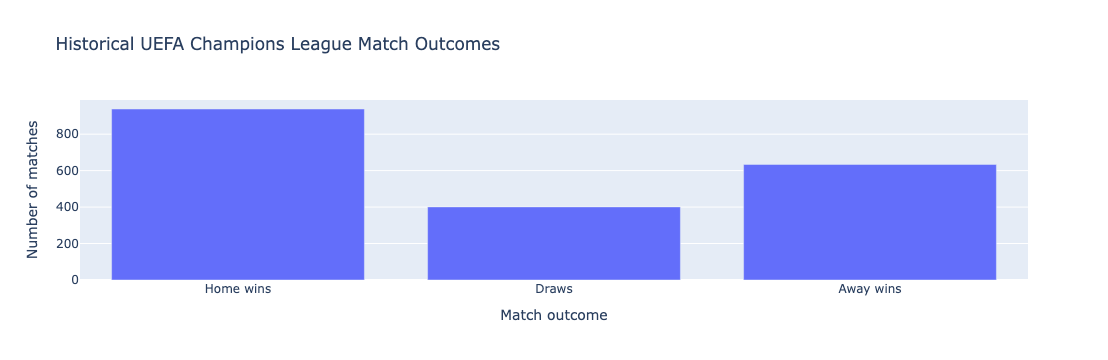

In [23]:
outcome_counts = matches["result"].value_counts().reindex(["H", "D", "A"], fill_value=0)
fig_outcomes = px.bar(
    x=["Home wins", "Draws", "Away wins"],
    y=outcome_counts.values,
    labels={"x": "Match outcome", "y": "Number of matches"},
    title="Historical UEFA Champions League Match Outcomes"
)
fig_outcomes.show()

In [24]:
def calculate_team_stats(history, current_date):
    if not history:
        return {
            "win_pct": 0.5, "points_rate": 0.5,
            "avg_goal_diff": 0.0, "avg_scored": 1.2,
            "avg_conceded": 1.2, "games": 0
        }

    ages = np.array([max(0, (current_date - game[0]).days) for game in history])
    weights = 0.5 ** (ages / HALF_LIFE_DAYS)

    scored = np.array([game[1] for game in history], dtype=float)
    conceded = np.array([game[2] for game in history], dtype=float)
    points = np.array([game[3] for game in history], dtype=float)
    total_weight = weights.sum()

    return {
        "win_pct": np.sum(weights * (points == 3)) / total_weight,
        "points_rate": np.sum(weights * points) / (3 * total_weight),
        "avg_goal_diff": np.sum(weights * (scored - conceded)) / total_weight,
        "avg_scored": np.sum(weights * scored) / total_weight,
        "avg_conceded": np.sum(weights * conceded) / total_weight,
        "games": len(history)
    }


def create_features(home_stats, away_stats):
    return [
        home_stats["win_pct"] - away_stats["win_pct"],
        home_stats["points_rate"] - away_stats["points_rate"],
        home_stats["avg_goal_diff"] - away_stats["avg_goal_diff"],
        home_stats["avg_scored"] - away_stats["avg_scored"],
        home_stats["avg_conceded"] - away_stats["avg_conceded"],
        home_stats["games"] - away_stats["games"],
        1  # home advantage
    ]


feature_names = [
    "win_pct_difference", "points_rate_difference",
    "goal_difference", "scoring_difference",
    "conceding_difference", "experience_difference",
    "home_advantage"
]

team_history = {}
feature_rows = []
target_rows = []
match_dates = []

# Process matches by date. Results from the current date are added only
# after every match on that date has had its features calculated.
for current_date, daily_matches in matches.groupby("date", sort=True):
    for _, row in daily_matches.iterrows():
        home = row["home_team"]
        away = row["away_team"]

        home_stats = calculate_team_stats(team_history.get(home, []), current_date)
        away_stats = calculate_team_stats(team_history.get(away, []), current_date)

        feature_rows.append(create_features(home_stats, away_stats))
        target_rows.append(row["result"])
        match_dates.append(current_date)

    for _, row in daily_matches.iterrows():
        home, away = row["home_team"], row["away_team"]
        hg, ag = int(row["home_goals"]), int(row["away_goals"])

        if hg > ag:
            home_points, away_points = 3, 0
        elif hg < ag:
            home_points, away_points = 0, 3
        else:
            home_points, away_points = 1, 1

        team_history.setdefault(home, []).append((current_date, hg, ag, home_points))
        team_history.setdefault(away, []).append((current_date, ag, hg, away_points))

X = pd.DataFrame(feature_rows, columns=feature_names)
y = np.array(target_rows)
match_dates = pd.Series(pd.to_datetime(match_dates))

print("Feature matrix:", X.shape)
print("Outcome classes:", sorted(pd.Series(y).unique()))
display(X.head())

Feature matrix: (1973, 7)
Outcome classes: ['A', 'D', 'H']


,win_pct_difference,points_rate_difference,goal_difference,scoring_difference,conceding_difference,experience_difference,home_advantage
0,0.0,0.0,0.0,0.0,0.0,0,1
1,0.0,0.0,0.0,0.0,0.0,0,1
2,0.0,0.0,0.0,0.0,0.0,0,1
3,0.0,0.0,0.0,0.0,0.0,0,1
4,0.0,0.0,0.0,0.0,0.0,0,1


In [25]:
if len(X) < 20:
    raise ValueError("Too few parsed matches for a meaningful chronological train/test split.")

split_index = int(len(X) * 0.80)
X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
y_train, y_test = y[:split_index], y[split_index:]
train_dates = match_dates.iloc[:split_index]

if len(np.unique(y_train)) < 2:
    raise ValueError("Training data contains fewer than two outcome classes.")

latest_train_date = train_dates.max()
training_ages = (latest_train_date - train_dates).dt.days.clip(lower=0)
sample_weights = 0.5 ** (training_ages / HALF_LIFE_DAYS)

model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)
)

model.fit(
    X_train,
    y_train,
    logisticregression__sample_weight=sample_weights
)

predictions = model.predict(X_test)

print("Training matches:", len(X_train))
print("Testing matches:", len(X_test))
print("Test period:", match_dates.iloc[split_index].date(), "to", match_dates.iloc[-1].date())
print("Test accuracy:", round(accuracy_score(y_test, predictions) * 100, 2), "%")
print("\nClassification report:")
print(classification_report(y_test, predictions, zero_division=0))

print("Confusion matrix class order:", list(model.classes_))
display(pd.DataFrame(
    confusion_matrix(y_test, predictions, labels=model.classes_),
    index=[f"Actual {c}" for c in model.classes_],
    columns=[f"Predicted {c}" for c in model.classes_]
))

majority_class = pd.Series(y_train).mode()[0]
baseline_predictions = np.repeat(majority_class, len(y_test))
baseline_accuracy = accuracy_score(y_test, baseline_predictions)
print("Majority-class baseline accuracy:", round(baseline_accuracy * 100, 2), "%")

Training matches: 1578
Testing matches: 395
Test period: 2024-02-13 to 2026-01-20
Test accuracy: 54.94 %

Classification report:
              precision    recall  f1-score   support

           A       0.49      0.50      0.50       131
           D       0.00      0.00      0.00        65
           H       0.58      0.76      0.66       199

    accuracy                           0.55       395
   macro avg       0.36      0.42      0.38       395
weighted avg       0.45      0.55      0.50       395

Confusion matrix class order: [np.str_('A'), np.str_('D'), np.str_('H')]


,Predicted A,Predicted D,Predicted H
Actual A,66,0,65
Actual D,20,0,45
Actual H,48,0,151


Majority-class baseline accuracy: 50.38 %


In [30]:
def predict_match(team1, team2):
    if team1 == team2:
        raise ValueError("Choose two different teams.")
    if team1 not in team_history or team2 not in team_history:
        raise ValueError("One or both teams are not present in the historical data.")

    prediction_date = matches["date"].max() + pd.Timedelta(days=1)
    stats1 = calculate_team_stats(team_history.get(team1, []), prediction_date)
    stats2 = calculate_team_stats(team_history.get(team2, []), prediction_date)

    # Team 1 at home
    row1 = pd.DataFrame([create_features(stats1, stats2)], columns=feature_names)
    probs1 = dict(zip(model.classes_, model.predict_proba(row1)[0]))

    # Team 2 at home
    row2 = pd.DataFrame([create_features(stats2, stats1)], columns=feature_names)
    probs2 = dict(zip(model.classes_, model.predict_proba(row2)[0]))

    team1_win = (probs1.get("H", 0) + probs2.get("A", 0)) / 2
    draw = (probs1.get("D", 0) + probs2.get("D", 0)) / 2
    team2_win = (probs1.get("A", 0) + probs2.get("H", 0)) / 2

    total = team1_win + draw + team2_win
    return {
        "Team 1 Win": team1_win / total,
        "Draw": draw / total,
        "Team 2 Win": team2_win / total
    }


example_team1 = PSG_NAME
example_team2 = "Real Madrid"

if example_team1 in team_history and example_team2 in team_history:
    example_result = predict_match(example_team1, example_team2)
    print(f"{example_team1} vs {example_team2}")
    for outcome, probability in example_result.items():
        print(f"{outcome}: {probability:.1%}")
else:
    print("Example team name not found. Check exact spellings in the team list.")

Example team name not found. Check exact spellings in the team list.


In [31]:
teams = sorted(set(matches["home_team"]) | set(matches["away_team"]))
team_ratings = []

for team in teams:
    expected_points_total = 0
    win_probability_total = 0
    opponent_count = 0

    for opponent in teams:
        if team == opponent:
            continue

        result = predict_match(team, opponent)
        win_probability = result["Team 1 Win"]
        draw_probability = result["Draw"]

        expected_points_total += 3 * win_probability + draw_probability
        win_probability_total += win_probability
        opponent_count += 1

    team_ratings.append({
        "Team": team,
        "Predicted Win %": 100 * win_probability_total / opponent_count,
        "Expected Points": expected_points_total / opponent_count
    })

rating_board = pd.DataFrame(team_ratings).sort_values(
    "Expected Points", ascending=False
).reset_index(drop=True)
rating_board.insert(0, "Rank", np.arange(1, len(rating_board) + 1))

display(rating_board.style.format({
    "Predicted Win %": "{:.1f}%",
    "Expected Points": "{:.3f}"
}))

,Rank,Team,Predicted Win %,Expected Points
0,1,Bayern München (GER),81.1%,2.555
1,2,FC Barcelona (ESP),77.3%,2.458
2,3,Manchester City (ENG),77.2%,2.455
3,4,Real Madrid (ESP),73.1%,2.347
4,5,Arsenal FC (ENG),70.7%,2.284
5,6,Paris Saint-Germain (FRA),69.9%,2.261
6,7,Borussia Dortmund (GER),68.4%,2.221
7,8,Liverpool FC (ENG),67.6%,2.200
8,9,Paris Saint-Germain FC (FRA),66.4%,2.167
9,10,FC Bayern München (GER),63.0%,2.076


In [32]:
psg_candidates = [
    team for team in teams
    if "paris saint-germain" in team.lower() or team.lower() == "psg"
]

if not psg_candidates:
    print("PSG was not found. Check the exact team names below.")
    display(pd.DataFrame({"Team names": teams}))
    psg_board = pd.DataFrame()
else:
    PSG_TEAM = psg_candidates[0]
    psg_predictions = []

    for team in teams:
        if team == PSG_TEAM:
            continue

        result = predict_match(team, PSG_TEAM)
        psg_predictions.append({
            "Team": team,
            "Win Against PSG (%)": result["Team 1 Win"] * 100,
            "Draw (%)": result["Draw"] * 100,
            "PSG Win (%)": result["Team 2 Win"] * 100
        })

    psg_board = pd.DataFrame(psg_predictions).sort_values(
        "Win Against PSG (%)", ascending=False
    ).reset_index(drop=True)
    psg_board.insert(0, "Rank", np.arange(1, len(psg_board) + 1))

    print("Predicted match probabilities against", PSG_TEAM)
    display(psg_board.style.format({
        "Win Against PSG (%)": "{:.1f}%",
        "Draw (%)": "{:.1f}%",
        "PSG Win (%)": "{:.1f}%"
    }))

Predicted match probabilities against Paris Saint-Germain (FRA)


,Rank,Team,Win Against PSG (%),Draw (%),PSG Win (%)
0,1,Bayern München (GER),56.6%,21.0%,22.4%
1,2,FC Barcelona (ESP),49.9%,22.0%,28.1%
2,3,Manchester City (ENG),49.8%,22.1%,28.1%
3,4,Real Madrid (ESP),43.2%,22.6%,34.1%
4,5,Arsenal FC (ENG),39.9%,22.8%,37.3%
5,6,Borussia Dortmund (GER),36.6%,22.8%,40.6%
6,7,Liverpool FC (ENG),35.7%,22.7%,41.6%
7,8,Paris Saint-Germain FC (FRA),34.3%,22.8%,42.9%
8,9,FC Bayern München (GER),30.4%,22.5%,47.1%
9,10,Chelsea FC (ENG),28.6%,22.1%,49.2%


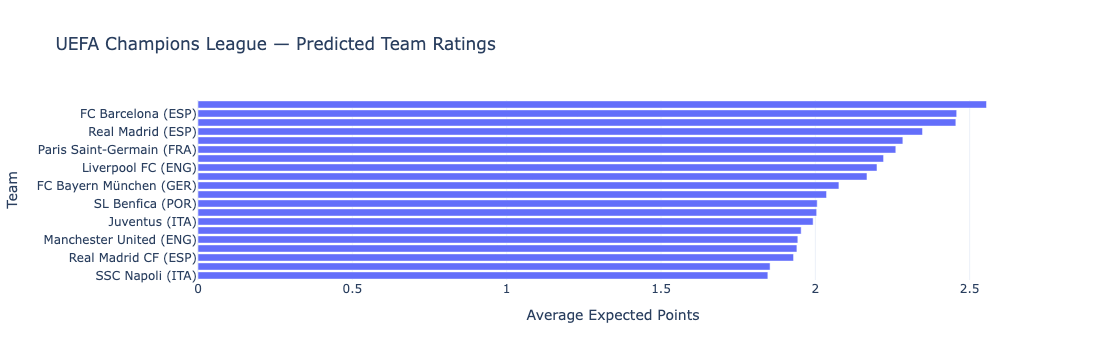

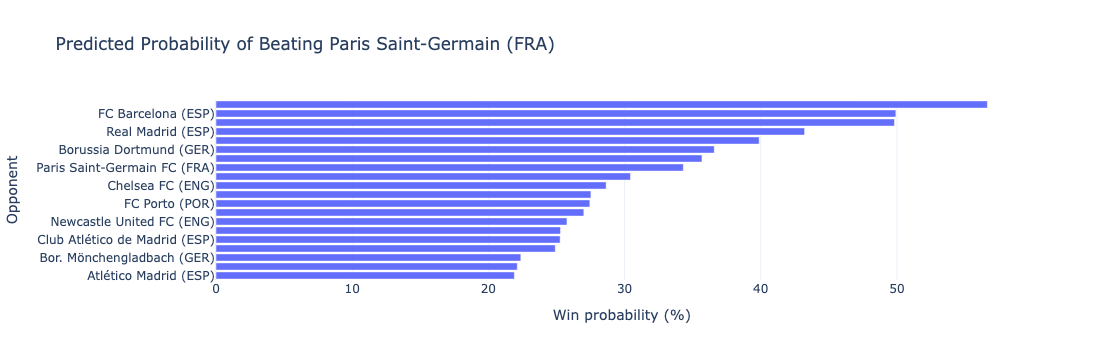

Individual HTML charts saved in: /Users/raosahebshinde/Downloads/data_math 215/dashboard


In [33]:
top_ratings = rating_board.head(20).sort_values("Expected Points")

fig_ranking = px.bar(
    top_ratings,
    x="Expected Points",
    y="Team",
    orientation="h",
    title="UEFA Champions League — Predicted Team Ratings",
    labels={"Expected Points": "Average Expected Points", "Team": "Team"}
)
fig_ranking.update_layout(template="plotly_white")
fig_ranking.show()

fig_ranking.write_html(
    OUTPUT_FOLDER / "team_ranking.html",
    include_plotlyjs=True
)

if not psg_board.empty:
    top_psg = psg_board.head(20).sort_values("Win Against PSG (%)")
    fig_psg = px.bar(
        top_psg,
        x="Win Against PSG (%)",
        y="Team",
        orientation="h",
        title=f"Predicted Probability of Beating {PSG_TEAM}",
        labels={"Win Against PSG (%)": "Win probability (%)", "Team": "Opponent"}
    )
    fig_psg.update_layout(template="plotly_white")
    fig_psg.show()
    fig_psg.write_html(
        OUTPUT_FOLDER / "psg_predictions.html",
        include_plotlyjs=True
    )

print("Individual HTML charts saved in:", OUTPUT_FOLDER.resolve())

In [34]:
ranking_table_html = rating_board.to_html(
    index=False, classes="data-table", border=0,
    float_format=lambda x: f"{x:.3f}"
)
ranking_chart_html = fig_ranking.to_html(
    full_html=False, include_plotlyjs=True
)

if not psg_board.empty:
    psg_table_html = psg_board.to_html(
        index=False, classes="data-table", border=0,
        float_format=lambda x: f"{x:.2f}"
    )
    psg_chart_html = fig_psg.to_html(
        full_html=False, include_plotlyjs=False
    )
else:
    psg_table_html = "<p>PSG was not found in the loaded season files.</p>"
    psg_chart_html = ""

dashboard_html = f'''
<!DOCTYPE html>
<html lang="en">
<head>
<meta charset="UTF-8">
<meta name="viewport" content="width=device-width, initial-scale=1.0">
<title>UEFA Champions League Prediction Dashboard</title>
<style>
body {{ font-family: Arial, sans-serif; margin: 30px; color: #202124; background: #f7f8fa; }}
h1, h2 {{ color: #172554; }}
section {{ background: white; padding: 22px; margin: 22px 0; border-radius: 10px; }}
.data-table {{ border-collapse: collapse; width: 100%; font-size: 14px; }}
.data-table th, .data-table td {{ border-bottom: 1px solid #ddd; padding: 9px; text-align: left; }}
.data-table th {{ background: #eef2ff; }}
.note {{ color: #555; line-height: 1.5; }}
</style>
</head>
<body>
<h1>UEFA Champions League Prediction Dashboard</h1>
<p class="note">Historical matches loaded: {len(matches)} |
Teams included: {len(teams)} |
Data through: {matches['date'].max().date()}</p>
<section>
<h2>Predicted Team Rankings</h2>
<p class="note">Teams are ranked by average model-estimated expected points against all other teams in the dataset.</p>
{ranking_chart_html}
{ranking_table_html}
</section>
<section>
<h2>Head-to-head comparison against PSG</h2>
<p class="note">Probabilities are model estimates, not guaranteed outcomes.</p>
{psg_chart_html}
{psg_table_html}
</section>
<section>
<h2>About this model</h2>
<p class="note">A Scikit-learn Logistic Regression model estimates home win, draw, and away win probabilities.
Historical match statistics use exponential recency weighting with a {HALF_LIFE_DAYS}-day half-life.
The model is retrained when this notebook is rerun with updated match files.</p>
</section>
</body>
</html>
'''

dashboard_path = OUTPUT_FOLDER / "index.html"
dashboard_path.write_text(dashboard_html, encoding="utf-8")
print("Main dashboard saved to:", dashboard_path.resolve())

Main dashboard saved to: /Users/raosahebshinde/Downloads/data_math 215/dashboard/index.html


In [35]:
joblib.dump(model, OUTPUT_FOLDER / "ucl_prediction_model.joblib")

metadata = {
    "feature_names": feature_names,
    "half_life_days": HALF_LIFE_DAYS,
    "latest_match_date": str(matches["date"].max().date()),
    "number_of_matches": int(len(matches)),
    "number_of_teams": int(len(teams)),
    "model_type": "Scikit-learn Logistic Regression"
}
pd.Series(metadata).to_json(OUTPUT_FOLDER / "model_metadata.json", indent=4)

rating_board.to_csv(OUTPUT_FOLDER / "team_ratings.csv", index=False)
if not psg_board.empty:
    psg_board.to_csv(OUTPUT_FOLDER / "psg_predictions.csv", index=False)

print("Model and supporting files saved in:", OUTPUT_FOLDER.resolve())

Model and supporting files saved in: /Users/raosahebshinde/Downloads/data_math 215/dashboard
